In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
from statsmodels.tsa.stattools import adfuller


In [6]:
#Importing Datasets
df = pd.read_csv(r'C:\Users\HP\Downloads\Nigeria_CO2_Emissions_1980_2024.csv')
df1 = pd.read_csv(r'C:\Users\HP\Downloads\Nigeria_Population_1980_2024 (1).csv')
df2 = pd.read_csv(r'C:\Users\HP\Downloads\Nigeria_GDP_1980_2024.csv')
df3 = pd.read_csv(r'C:\Users\HP\Downloads\primary energy used.csv')

In [7]:
df

,Year,Annual CO2 Emissions (tonnes)
0,1980,"67,986,780"
1,1981,"65,750,932"
2,1982,"65,309,068"
3,1983,"59,622,080"
4,1984,"69,337,910"
5,1985,"69,561,390"
6,1986,"73,107,380"
7,1987,"58,942,336"
8,1988,"70,347,070"
9,1989,"42,046,410"


In [8]:
df1

,Year,Population
0,1980,"73,764,641"
1,1981,"76,068,116"
2,1982,"78,378,699"
3,1983,"80,438,257"
4,1984,"82,526,444"
5,1985,"84,897,973"
6,1986,"87,235,959"
7,1987,"89,591,718"
8,1988,"92,020,088"
9,1989,"94,531,022"


In [9]:
df2

,Year,GDP (current US$)
0,1980,"64,201,788,123"
1,1981,"164,475,000,000"
2,1982,"142,769,000,000"
3,1983,"97,094,911,792"
4,1984,"73,484,359,521"
5,1985,"73,745,821,158"
6,1986,"54,805,852,581"
7,1987,"52,676,041,931"
8,1988,"49,648,470,440"
9,1989,"44,003,061,108"


In [10]:
df3

,Entity,Code,Year,Total energy supply
0,Nigeria,NGA,1980,116.95822
1,Nigeria,NGA,1981,146.00766
2,Nigeria,NGA,1982,146.89717
3,Nigeria,NGA,1983,148.01225
4,Nigeria,NGA,1984,158.71999
5,Nigeria,NGA,1985,169.30699
6,Nigeria,NGA,1986,164.13889
7,Nigeria,NGA,1987,174.51772
8,Nigeria,NGA,1988,186.25883
9,Nigeria,NGA,1989,201.94217


In [11]:
# Merging Dataframes

In [12]:
p_combine = df.merge(df1, how = 'inner', on = 'Year')

In [13]:
p_combine

,Year,Annual CO2 Emissions (tonnes),Population
0,1980,"67,986,780","73,764,641"
1,1981,"65,750,932","76,068,116"
2,1982,"65,309,068","78,378,699"
3,1983,"59,622,080","80,438,257"
4,1984,"69,337,910","82,526,444"
5,1985,"69,561,390","84,897,973"
6,1986,"73,107,380","87,235,959"
7,1987,"58,942,336","89,591,718"
8,1988,"70,347,070","92,020,088"
9,1989,"42,046,410","94,531,022"


In [14]:
p_combine1= p_combine.merge(df2, how = 'inner' , on = 'Year')

In [15]:
p_combine1

,Year,Annual CO2 Emissions (tonnes),Population,GDP (current US$)
0,1980,"67,986,780","73,764,641","64,201,788,123"
1,1981,"65,750,932","76,068,116","164,475,000,000"
2,1982,"65,309,068","78,378,699","142,769,000,000"
3,1983,"59,622,080","80,438,257","97,094,911,792"
4,1984,"69,337,910","82,526,444","73,484,359,521"
5,1985,"69,561,390","84,897,973","73,745,821,158"
6,1986,"73,107,380","87,235,959","54,805,852,581"
7,1987,"58,942,336","89,591,718","52,676,041,931"
8,1988,"70,347,070","92,020,088","49,648,470,440"
9,1989,"42,046,410","94,531,022","44,003,061,108"


In [16]:
p_combine2 = p_combine1.merge(df3, how = 'inner', on = 'Year')

In [17]:
p_combine2

,Year,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Entity,Code,Total energy supply
0,1980,"67,986,780","73,764,641","64,201,788,123",Nigeria,NGA,116.95822
1,1981,"65,750,932","76,068,116","164,475,000,000",Nigeria,NGA,146.00766
2,1982,"65,309,068","78,378,699","142,769,000,000",Nigeria,NGA,146.89717
3,1983,"59,622,080","80,438,257","97,094,911,792",Nigeria,NGA,148.01225
4,1984,"69,337,910","82,526,444","73,484,359,521",Nigeria,NGA,158.71999
5,1985,"69,561,390","84,897,973","73,745,821,158",Nigeria,NGA,169.30699
6,1986,"73,107,380","87,235,959","54,805,852,581",Nigeria,NGA,164.13889
7,1987,"58,942,336","89,591,718","52,676,041,931",Nigeria,NGA,174.51772
8,1988,"70,347,070","92,020,088","49,648,470,440",Nigeria,NGA,186.25883
9,1989,"42,046,410","94,531,022","44,003,061,108",Nigeria,NGA,201.94217


In [18]:
#reordering the columns

In [19]:
new_order = ['Entity', 'Code', 'Year', 'Annual CO2 Emissions (tonnes)', 
             'Population', 'GDP (current US$)', 'Total energy supply']

p_combine2 = p_combine2[new_order]

In [20]:
p_combine2

,Entity,Code,Year,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply
0,Nigeria,NGA,1980,"67,986,780","73,764,641","64,201,788,123",116.95822
1,Nigeria,NGA,1981,"65,750,932","76,068,116","164,475,000,000",146.00766
2,Nigeria,NGA,1982,"65,309,068","78,378,699","142,769,000,000",146.89717
3,Nigeria,NGA,1983,"59,622,080","80,438,257","97,094,911,792",148.01225
4,Nigeria,NGA,1984,"69,337,910","82,526,444","73,484,359,521",158.71999
5,Nigeria,NGA,1985,"69,561,390","84,897,973","73,745,821,158",169.30699
6,Nigeria,NGA,1986,"73,107,380","87,235,959","54,805,852,581",164.13889
7,Nigeria,NGA,1987,"58,942,336","89,591,718","52,676,041,931",174.51772
8,Nigeria,NGA,1988,"70,347,070","92,020,088","49,648,470,440",186.25883
9,Nigeria,NGA,1989,"42,046,410","94,531,022","44,003,061,108",201.94217


In [21]:
p_combine2['GDP (current US$)'] = p_combine2['GDP (current US$)'].str.replace(',','').astype(float)

In [22]:
p_combine2['GDP (current US$)'].describe()

count    4.500000e+01
mean     2.450514e+11
std      1.967911e+11
min      4.400306e+10
25%      7.348436e+10
50%      1.756710e+11
75%      4.046490e+11
max      6.682200e+11
Name: GDP (current US$), dtype: float64

In [23]:
p_combine2['GDP (current US$)'].dtype

dtype('float64')

In [24]:
p_combine2['Annual CO2 Emissions (tonnes)']=p_combine2['Annual CO2 Emissions (tonnes)'].str.replace(',', '').astype(float)

In [25]:
p_combine2['Population']=p_combine2['Population'].str.replace(',','').astype(float)

In [26]:
p_combine2 = p_combine2.set_index('Year')


In [27]:
p_combine2

,Entity,Code,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply
Year,,,,,,
1980,Nigeria,NGA,67986780.0,73764641.0,6.420179e+10,116.95822
1981,Nigeria,NGA,65750932.0,76068116.0,1.644750e+11,146.00766
1982,Nigeria,NGA,65309068.0,78378699.0,1.427690e+11,146.89717
1983,Nigeria,NGA,59622080.0,80438257.0,9.709491e+10,148.01225
1984,Nigeria,NGA,69337910.0,82526444.0,7.348436e+10,158.71999
1985,Nigeria,NGA,69561390.0,84897973.0,7.374582e+10,169.30699
1986,Nigeria,NGA,73107380.0,87235959.0,5.480585e+10,164.13889
1987,Nigeria,NGA,58942336.0,89591718.0,5.267604e+10,174.51772
1988,Nigeria,NGA,70347070.0,92020088.0,4.964847e+10,186.25883


In [28]:
#Summary Statistics

In [29]:
summary_statistics = p_combine2.describe()

In [30]:
summary_statistics

,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply
count,4.500000e+01,4.500000e+01,4.500000e+01,45.000000
mean,9.100384e+07,1.415363e+08,2.450514e+11,294.520249
std,2.801533e+07,4.839358e+07,1.967911e+11,129.825314
min,3.878560e+07,7.376464e+07,4.400306e+10,116.958220
25%,6.956139e+07,9.972016e+07,7.348436e+10,201.942170
50%,9.009715e+07,1.334720e+08,1.756710e+11,240.845370
75%,1.120498e+08,1.810494e+08,4.046490e+11,453.332520
max,1.477766e+08,2.326800e+08,6.682200e+11,527.352300


In [31]:
summary_statistics= p_combine2.describe().apply(lambda x: x.map('{:,.2f}'.format))

In [32]:
summary_statistics

,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply
count,45.00,45.00,45.00,45.00
mean,"91,003,837.78","141,536,302.40","245,051,360,217.93",294.52
std,"28,015,329.49","48,393,575.42","196,791,113,859.55",129.83
min,"38,785,600.00","73,764,641.00","44,003,061,108.00",116.96
25%,"69,561,390.00","99,720,161.00","73,484,359,521.00",201.94
50%,"90,097,150.00","133,471,995.00","175,671,000,000.00",240.85
75%,"112,049,800.00","181,049,440.00","404,649,000,000.00",453.33
max,"147,776,620.00","232,680,000.00","668,220,000,000.00",527.35


In [33]:
print(p_combine2.dtypes)

Entity                            object
Code                              object
Annual CO2 Emissions (tonnes)    float64
Population                       float64
GDP (current US$)                float64
Total energy supply              float64
dtype: object


In [34]:
p_combine2 = p_combine2.apply(lambda col: pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce') if col.name not in ['Entity', 'Code'] else col)

In [35]:
p_combine2

,Entity,Code,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply
Year,,,,,,
1980,Nigeria,NGA,67986780.0,73764641.0,6.420179e+10,116.95822
1981,Nigeria,NGA,65750932.0,76068116.0,1.644750e+11,146.00766
1982,Nigeria,NGA,65309068.0,78378699.0,1.427690e+11,146.89717
1983,Nigeria,NGA,59622080.0,80438257.0,9.709491e+10,148.01225
1984,Nigeria,NGA,69337910.0,82526444.0,7.348436e+10,158.71999
1985,Nigeria,NGA,69561390.0,84897973.0,7.374582e+10,169.30699
1986,Nigeria,NGA,73107380.0,87235959.0,5.480585e+10,164.13889
1987,Nigeria,NGA,58942336.0,89591718.0,5.267604e+10,174.51772
1988,Nigeria,NGA,70347070.0,92020088.0,4.964847e+10,186.25883


In [36]:
#correlation Heatmap

In [37]:
df_numeric = p_combine2.drop(columns = ['Entity','Code'])

In [38]:
df_numeric

,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply
Year,,,,
1980,67986780.0,73764641.0,6.420179e+10,116.95822
1981,65750932.0,76068116.0,1.644750e+11,146.00766
1982,65309068.0,78378699.0,1.427690e+11,146.89717
1983,59622080.0,80438257.0,9.709491e+10,148.01225
1984,69337910.0,82526444.0,7.348436e+10,158.71999
1985,69561390.0,84897973.0,7.374582e+10,169.30699
1986,73107380.0,87235959.0,5.480585e+10,164.13889
1987,58942336.0,89591718.0,5.267604e+10,174.51772
1988,70347070.0,92020088.0,4.964847e+10,186.25883


In [39]:
p_combine2["pop_growth"] = 100 * np.log(p_combine2["Population"]).diff()

In [40]:
p_combine2

,Entity,Code,Annual CO2 Emissions (tonnes),Population,GDP (current US$),Total energy supply,pop_growth
Year,,,,,,,
1980,Nigeria,NGA,67986780.0,73764641.0,6.420179e+10,116.95822,NaN
1981,Nigeria,NGA,65750932.0,76068116.0,1.644750e+11,146.00766,3.074970
1982,Nigeria,NGA,65309068.0,78378699.0,1.427690e+11,146.89717,2.992299
1983,Nigeria,NGA,59622080.0,80438257.0,9.709491e+10,148.01225,2.593770
1984,Nigeria,NGA,69337910.0,82526444.0,7.348436e+10,158.71999,2.562888
1985,Nigeria,NGA,69561390.0,84897973.0,7.374582e+10,169.30699,2.833144
1986,Nigeria,NGA,73107380.0,87235959.0,5.480585e+10,164.13889,2.716640
1987,Nigeria,NGA,58942336.0,89591718.0,5.267604e+10,174.51772,2.664626
1988,Nigeria,NGA,70347070.0,92020088.0,4.964847e+10,186.25883,2.674402


<Axes: >

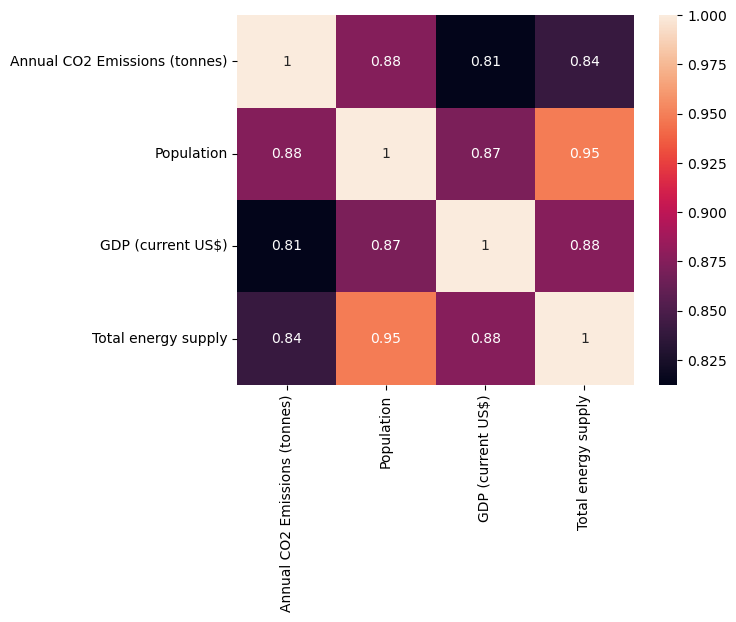

In [41]:
sns.heatmap(df_numeric.corr(),annot=True)

In [42]:
#Time Series Plot

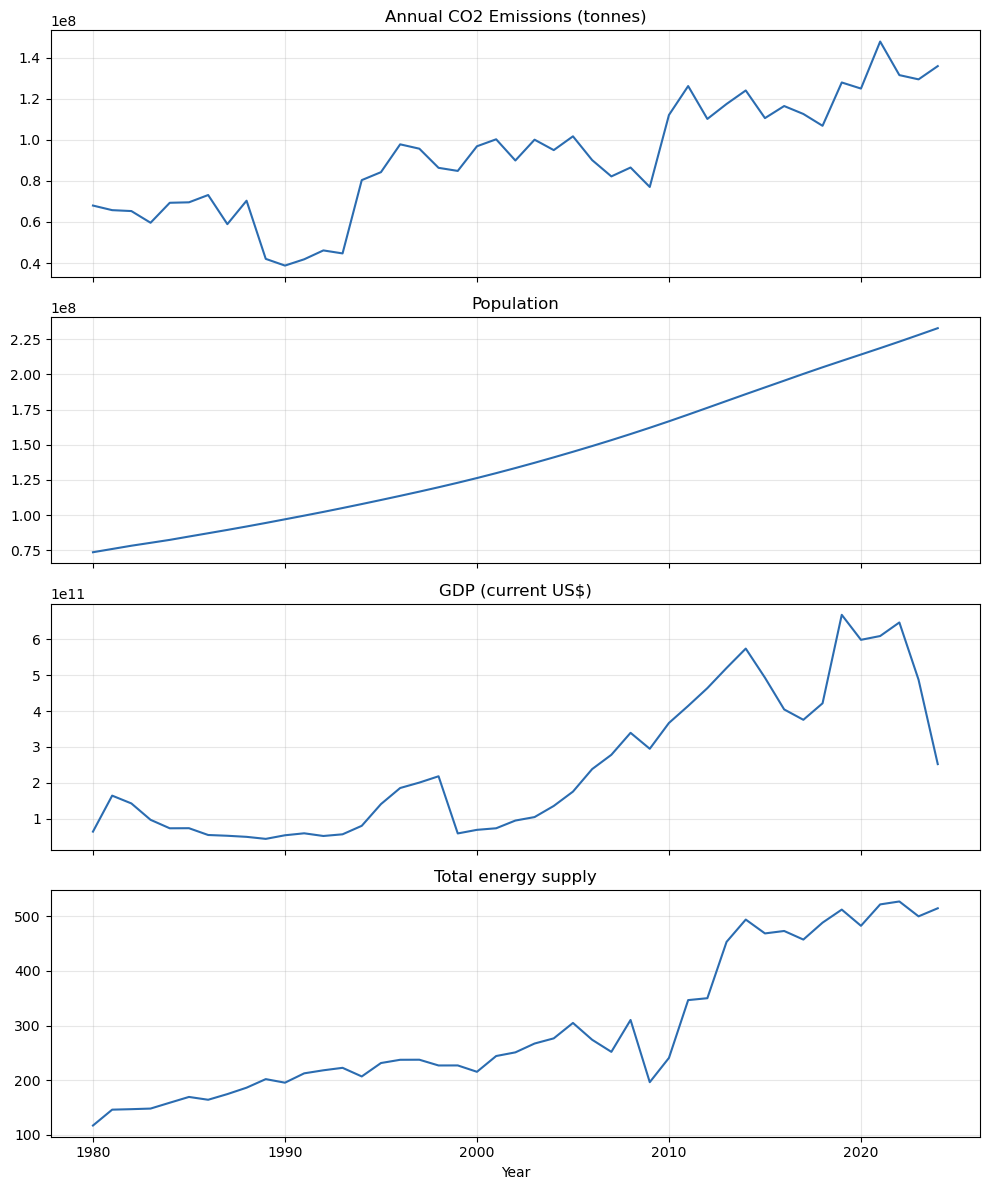

In [43]:
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
for ax, col in zip(axes, df_numeric.columns):
    df_numeric[col].plot(ax=ax, color='#2b6cb0')
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Year')
plt.tight_layout()
plt.show() 

In [44]:
#Test for Stationarity(Time series Model)

In [45]:
from statsmodels.tsa.stattools import adfuller

def adf_test(series, name):
    result = adfuller(series.dropna())
    print(f"{name}:")
    print(f"  ADF Statistic = {result[0]:.4f}")
    print(f"  p-value = {result[1]:.4f}")
    print(f"  Critical Values: {result[4]}")
    if result[1] > 0.05:
        print("  → Non-stationary (fail to reject H0)\n")
    else:
        print("  → Stationary (reject H0)\n")

for col in df_numeric.columns:  
    adf_test(p_combine2[col], col)

Annual CO2 Emissions (tonnes):
  ADF Statistic = -1.1775
  p-value = 0.6832
  Critical Values: {'1%': np.float64(-3.5885733964124715), '5%': np.float64(-2.929885661157025), '10%': np.float64(-2.6031845661157025)}
  → Non-stationary (fail to reject H0)

Population:
  ADF Statistic = 1.9458
  p-value = 0.9986
  Critical Values: {'1%': np.float64(-3.6155091011809297), '5%': np.float64(-2.941262357486514), '10%': np.float64(-2.6091995013850418)}
  → Non-stationary (fail to reject H0)

GDP (current US$):
  ADF Statistic = -1.5818
  p-value = 0.4927
  Critical Values: {'1%': np.float64(-3.5925042342183704), '5%': np.float64(-2.931549768951162), '10%': np.float64(-2.60406594375338)}
  → Non-stationary (fail to reject H0)

Total energy supply:
  ADF Statistic = -0.1475
  p-value = 0.9445
  Critical Values: {'1%': np.float64(-3.6055648906249997), '5%': np.float64(-2.937069375), '10%': np.float64(-2.606985625)}
  → Non-stationary (fail to reject H0)



In [46]:
print(df_numeric.dtypes)

Annual CO2 Emissions (tonnes)    float64
Population                       float64
GDP (current US$)                float64
Total energy supply              float64
dtype: object


In [47]:
#Differencing to achieve stationarity

In [48]:
# First difference all four variables
df_diff = df_numeric.diff().dropna()

# Re-run ADF test on differenced series
for col in df_diff.columns:
    adf_test(df_diff[col], f"{col} (1st difference)")

Annual CO2 Emissions (tonnes) (1st difference):
  ADF Statistic = -8.1493
  p-value = 0.0000
  Critical Values: {'1%': np.float64(-3.5925042342183704), '5%': np.float64(-2.931549768951162), '10%': np.float64(-2.60406594375338)}
  → Stationary (reject H0)

Population (1st difference):
  ADF Statistic = -0.7389
  p-value = 0.8364
  Critical Values: {'1%': np.float64(-3.6327426647230316), '5%': np.float64(-2.9485102040816327), '10%': np.float64(-2.6130173469387756)}
  → Non-stationary (fail to reject H0)

GDP (current US$) (1st difference):
  ADF Statistic = -4.4081
  p-value = 0.0003
  Critical Values: {'1%': np.float64(-3.5925042342183704), '5%': np.float64(-2.931549768951162), '10%': np.float64(-2.60406594375338)}
  → Stationary (reject H0)

Total energy supply (1st difference):
  ADF Statistic = -3.8417
  p-value = 0.0025
  Critical Values: {'1%': np.float64(-3.6055648906249997), '5%': np.float64(-2.937069375), '10%': np.float64(-2.606985625)}
  → Stationary (reject H0)



In [49]:
#Log difference transformation(Population)
pop_log_diff = np.log(df_numeric['Population']).diff().dropna()
adf_test(pop_log_diff, 'Population (log, 1st difference)')

Population (log, 1st difference):
  ADF Statistic = -1.7807
  p-value = 0.3901
  Critical Values: {'1%': np.float64(-3.626651907578875), '5%': np.float64(-2.9459512825788754), '10%': np.float64(-2.6116707716049383)}
  → Non-stationary (fail to reject H0)



In [50]:
p_combine2 = p_combine2.drop(columns='GDP (current US$)')

In [51]:
print(p_combine2.columns.tolist())

['Entity', 'Code', 'Annual CO2 Emissions (tonnes)', 'Population', 'Total energy supply', 'pop_growth']


In [52]:
p_combine2

,Entity,Code,Annual CO2 Emissions (tonnes),Population,Total energy supply,pop_growth
Year,,,,,,
1980,Nigeria,NGA,67986780.0,73764641.0,116.95822,NaN
1981,Nigeria,NGA,65750932.0,76068116.0,146.00766,3.074970
1982,Nigeria,NGA,65309068.0,78378699.0,146.89717,2.992299
1983,Nigeria,NGA,59622080.0,80438257.0,148.01225,2.593770
1984,Nigeria,NGA,69337910.0,82526444.0,158.71999,2.562888
1985,Nigeria,NGA,69561390.0,84897973.0,169.30699,2.833144
1986,Nigeria,NGA,73107380.0,87235959.0,164.13889,2.716640
1987,Nigeria,NGA,58942336.0,89591718.0,174.51772,2.664626
1988,Nigeria,NGA,70347070.0,92020088.0,186.25883,2.674402


In [53]:
p_combine2 = p_combine2.drop(columns='pop_growth')

In [54]:
p_combine2 

,Entity,Code,Annual CO2 Emissions (tonnes),Population,Total energy supply
Year,,,,,
1980,Nigeria,NGA,67986780.0,73764641.0,116.95822
1981,Nigeria,NGA,65750932.0,76068116.0,146.00766
1982,Nigeria,NGA,65309068.0,78378699.0,146.89717
1983,Nigeria,NGA,59622080.0,80438257.0,148.01225
1984,Nigeria,NGA,69337910.0,82526444.0,158.71999
1985,Nigeria,NGA,69561390.0,84897973.0,169.30699
1986,Nigeria,NGA,73107380.0,87235959.0,164.13889
1987,Nigeria,NGA,58942336.0,89591718.0,174.51772
1988,Nigeria,NGA,70347070.0,92020088.0,186.25883


In [55]:
df5 = pd.read_csv(r'C:\Users\HP\Documents\nigeria_gdp_per_capita_1980_2024.csv')

In [56]:
df5

,Year,GDP_per_capita_constant_2015_US$
0,1980,2177.415787
1,1981,1834.287608
2,1982,1659.098144
3,1983,1440.017478
4,1984,1387.921760
5,1985,1428.927428
6,1986,1391.478772
7,1987,1398.248833
8,1988,1461.191322
9,1989,1449.680176


In [57]:
p_combine3 = p_combine2.merge(df5, on= 'Year', how = 'inner')

In [58]:
p_combine3

,Year,Entity,Code,Annual CO2 Emissions (tonnes),Population,Total energy supply,GDP_per_capita_constant_2015_US$
0,1980,Nigeria,NGA,67986780.0,73764641.0,116.95822,2177.415787
1,1981,Nigeria,NGA,65750932.0,76068116.0,146.00766,1834.287608
2,1982,Nigeria,NGA,65309068.0,78378699.0,146.89717,1659.098144
3,1983,Nigeria,NGA,59622080.0,80438257.0,148.01225,1440.017478
4,1984,Nigeria,NGA,69337910.0,82526444.0,158.71999,1387.921760
5,1985,Nigeria,NGA,69561390.0,84897973.0,169.30699,1428.927428
6,1986,Nigeria,NGA,73107380.0,87235959.0,164.13889,1391.478772
7,1987,Nigeria,NGA,58942336.0,89591718.0,174.51772,1398.248833
8,1988,Nigeria,NGA,70347070.0,92020088.0,186.25883,1461.191322
9,1989,Nigeria,NGA,42046410.0,94531022.0,201.94217,1449.680176


In [59]:
p_combine3.set_index('Year', inplace =True)

In [60]:
p_combine3

,Entity,Code,Annual CO2 Emissions (tonnes),Population,Total energy supply,GDP_per_capita_constant_2015_US$
Year,,,,,,
1980,Nigeria,NGA,67986780.0,73764641.0,116.95822,2177.415787
1981,Nigeria,NGA,65750932.0,76068116.0,146.00766,1834.287608
1982,Nigeria,NGA,65309068.0,78378699.0,146.89717,1659.098144
1983,Nigeria,NGA,59622080.0,80438257.0,148.01225,1440.017478
1984,Nigeria,NGA,69337910.0,82526444.0,158.71999,1387.921760
1985,Nigeria,NGA,69561390.0,84897973.0,169.30699,1428.927428
1986,Nigeria,NGA,73107380.0,87235959.0,164.13889,1391.478772
1987,Nigeria,NGA,58942336.0,89591718.0,174.51772,1398.248833
1988,Nigeria,NGA,70347070.0,92020088.0,186.25883,1461.191322


In [61]:
Real_summary = p_combine3.describe()
Real_summary 

,Annual CO2 Emissions (tonnes),Population,Total energy supply,GDP_per_capita_constant_2015_US$
count,4.500000e+01,4.500000e+01,45.000000,45.000000
mean,9.100384e+07,1.415363e+08,294.520249,1874.756057
std,2.801533e+07,4.839358e+07,129.825314,429.130995
min,3.878560e+07,7.376464e+07,116.958220,1387.921760
25%,6.956139e+07,9.972016e+07,201.942170,1440.017478
50%,9.009715e+07,1.334720e+08,240.845370,1824.802695
75%,1.120498e+08,1.810494e+08,453.332520,2280.677772
max,1.477766e+08,2.326800e+08,527.352300,2585.733607


In [62]:
Real_summary= p_combine3.describe().apply(lambda x: x.map('{:,.2f}'.format))
Real_summary

,Annual CO2 Emissions (tonnes),Population,Total energy supply,GDP_per_capita_constant_2015_US$
count,45.00,45.00,45.00,45.00
mean,"91,003,837.78","141,536,302.40",294.52,"1,874.76"
std,"28,015,329.49","48,393,575.42",129.83,429.13
min,"38,785,600.00","73,764,641.00",116.96,"1,387.92"
25%,"69,561,390.00","99,720,161.00",201.94,"1,440.02"
50%,"90,097,150.00","133,471,995.00",240.85,"1,824.80"
75%,"112,049,800.00","181,049,440.00",453.33,"2,280.68"
max,"147,776,620.00","232,680,000.00",527.35,"2,585.73"


In [63]:
p_combine3 = p_combine3.apply(lambda s: pd.to_numeric(s.astype(str).str.replace(",", "").str.strip(), errors="coerce"))
print(p_combine3.dtypes)
print(p_combine3.isna().sum())

Entity                              float64
Code                                float64
Annual CO2 Emissions (tonnes)       float64
Population                          float64
Total energy supply                 float64
GDP_per_capita_constant_2015_US$    float64
dtype: object
Entity                              45
Code                                45
Annual CO2 Emissions (tonnes)        0
Population                           0
Total energy supply                  0
GDP_per_capita_constant_2015_US$     0
dtype: int64


In [64]:
p_combine3 = p_combine3.drop(columns=["Entity", "Code"])
print(p_combine3.columns.tolist())

['Annual CO2 Emissions (tonnes)', 'Population', 'Total energy supply', 'GDP_per_capita_constant_2015_US$']


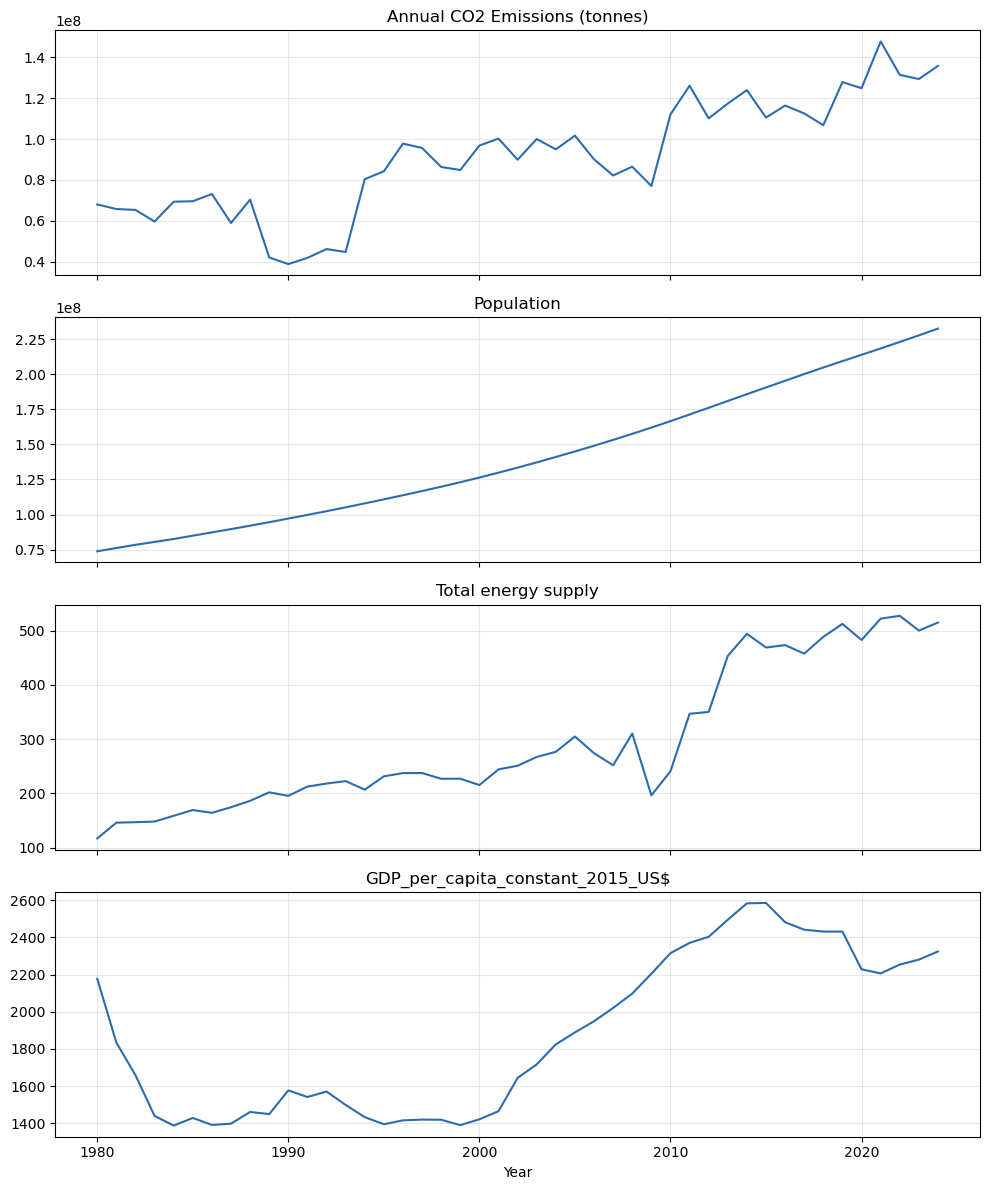

In [65]:
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
for ax, col in zip(axes, p_combine3.columns):
    p_combine3[col].plot(ax=ax, color='#2b6cb0')
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Year')
plt.tight_layout()
plt.show() 

<Axes: >

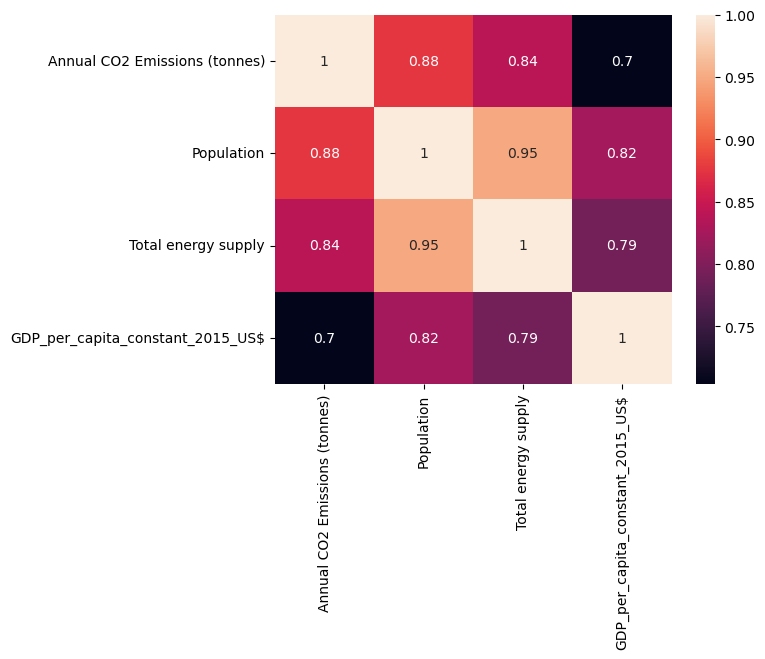

In [66]:
sns.heatmap(p_combine3.corr(),annot=True)

In [67]:
import numpy as np, pandas as pd, warnings
from statsmodels.tsa.stattools import adfuller, kpss
warnings.filterwarnings("ignore")

df = p_combine3.sort_index().rename(columns={
    "Annual CO2 Emissions (tonnes)": "lnCO2",
    "Population": "lnPOP",
    "Total energy supply": "lnTES",
    "GDP_per_capita_constant_2015_US$": "lnGDPpc"})
logs = np.log(df)

def test(x, reg):
    x = x.dropna()
    a = adfuller(x, regression=reg, maxlag=3, autolag="AIC")[1]
    k = kpss(x, regression=reg, nlags="auto")[1]
    return round(a, 4), round(k, 4)

rows = []
for c in logs.columns:
    s = logs[c]
    for name, x, reg in [("level", s, "ct"), ("diff1", s.diff(), "c"), ("diff2", s.diff().diff(), "c")]:
        a, k = test(x, reg)
        rows.append([c, name, a, k, "stationary" if (a < 0.05 and k > 0.05) else "not clear"])
pd.DataFrame(rows, columns=["series", "form", "ADF p", "KPSS p", "verdict"])

,series,form,ADF p,KPSS p,verdict
0,lnCO2,level,0.1387,0.1000,not clear
1,lnCO2,diff1,0.0000,0.1000,stationary
2,lnCO2,diff2,0.0000,0.1000,stationary
3,lnPOP,level,0.0013,0.0502,stationary
4,lnPOP,diff1,0.9799,0.0386,not clear
5,lnPOP,diff2,0.5367,0.1000,not clear
6,lnTES,level,0.0853,0.1000,not clear
7,lnTES,diff1,0.0059,0.1000,stationary
8,lnTES,diff2,0.0000,0.1000,stationary
9,lnGDPpc,level,0.4129,0.0419,not clear


In [68]:
from statsmodels.tsa.stattools import adfuller, kpss
p = logs["lnPOP"]
print("ADF c :", round(adfuller(p, regression="c",  maxlag=3, autolag="AIC")[1], 4))
print("ADF ct:", round(adfuller(p, regression="ct", maxlag=3, autolag="AIC")[1], 4))
print("KPSS ct:", round(kpss(p, regression="ct", nlags="auto")[1], 4))

ADF c : 0.2071
ADF ct: 0.0013
KPSS ct: 0.0502


In [69]:
from statsmodels.tsa.ardl import ardl_select_order, UECM
y = logs["lnCO2"]
X = logs[["lnPOP", "lnTES", "lnGDPpc"]]
sel = ardl_select_order(y, 2, X, 2, ic="aic", trend="c")
print(sel.model.ardl_order)
uecm = UECM.from_ardl(sel.model).fit()
print(uecm.bounds_test(case=3)) 

(1, 0, 1, 2)


ValueError: All included exog variables must have a lag length >= 1

In [78]:
from statsmodels.tsa.ardl import UECM

uecm = UECM(
    y, 1, X,
    order={"lnPOP": 1, "lnTES": 1, "lnGDPpc": 2},
    trend="c"
).fit()

print(uecm.summary())
print(uecm.bounds_test(case=3))

                              UECM Model Results                              
Dep. Variable:                D.lnCO2   No. Observations:                   45
Model:               UECM(1, 1, 1, 2)   Log Likelihood                  30.162
Method:               Conditional MLE   S.D. of innovations             18.063
Date:                Wed, 18 Nov 2026   AIC                            -40.323
Time:                        11:05:35   BIC                            -22.482
Sample:                             2   HQIC                           -33.707
                                   45                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -8.4162      3.654     -2.304      0.027     -15.833      -0.999
lnCO2.L1        -0.4664      0.115     -4.039      0.000      -0.701      -0.232
lnPOP.L1         1.1409      0.310      3.67

In [79]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera

res = uecm.resid
print("resid std:", round(res.std(), 4))
print(acorr_ljungbox(res, lags=[1, 2, 3], return_df=True))
print("Jarque-Bera:", jarque_bera(res))

p = uecm.params
lr = {v: -p[f"{v}.L1"] / p["lnCO2.L1"] for v in ["lnPOP", "lnTES", "lnGDPpc"]}
lr["const"] = -p["const"] / p["lnCO2.L1"]
print(lr)

from statsmodels.stats.outliers_influence import variance_inflation_factor
Z = logs[["lnPOP", "lnTES", "lnGDPpc"]].assign(c=1.0)
print({c: round(variance_inflation_factor(Z.values, i), 1) for i, c in enumerate(Z.columns) if c != "c"})

resid std: 0.3647
     lb_stat     lb_pvalue
1  35.351486  2.752584e-09
2  59.702246  1.085980e-13
3  74.065477  5.746233e-16
Jarque-Bera: SignificanceResult(statistic=np.float64(6.186790980087242), pvalue=np.float64(0.045347714978882625))
{'lnPOP': np.float64(2.4461929272633047), 'lnTES': np.float64(-0.4210963162582379), 'lnGDPpc': np.float64(-1.1311168129727638), 'const': np.float64(-18.045070427197746)}
{'lnPOP': np.float64(12.2), 'lnTES': np.float64(10.3), 'lnGDPpc': np.float64(2.7)}


In [80]:
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Check 1: are the residuals really autocorrelated, or is the first value distorting them?
res = uecm.resid
print("number of residuals:", len(res))
print(res.head(4))
r = res.iloc[1:]
print("std without first:", round(r.std(), 4))
print(acorr_ljungbox(r, lags=[1, 2, 3], return_df=True))
print("Jarque-Bera:", jarque_bera(r))

# Check 2: does energy per person fix the overlap between variables?
Z2 = pd.DataFrame({"lnPOP": logs["lnPOP"],
                   "lnTESpc": logs["lnTES"] - logs["lnPOP"],
                   "lnGDPpc": logs["lnGDPpc"], "c": 1.0})
print({c: round(variance_inflation_factor(Z2.values, i), 1)
       for i, c in enumerate(Z2.columns) if c != "c"})


number of residuals: 43
Year
1982    17.976792
1983    17.957934
1984    17.982302
1985    18.145412
dtype: float64
std without first: 0.3662
     lb_stat     lb_pvalue
1  34.362449  4.574649e-09
2  57.944997  2.614591e-13
3  72.142631  1.483755e-15
Jarque-Bera: SignificanceResult(statistic=np.float64(6.85824792949573), pvalue=np.float64(0.03241532530584338))
{'lnPOP': np.float64(2.9), 'lnTESpc': np.float64(1.2), 'lnGDPpc': np.float64(2.7)}


In [ ]:
from statsmodels.tsa.ardl import ardl_select_order, UECM
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera

logs["lnTESpc"] = logs["lnTES"] - logs["lnPOP"]
y = logs["lnCO2"]
X = logs[["lnPOP", "lnTESpc", "lnGDPpc"]]

sel = ardl_select_order(y, 2, X, 2, ic="aic", trend="c")
o = sel.model.ardl_order
print("chosen order:", o)

order = {"lnPOP": max(1, o[1]), "lnTESpc": max(1, o[2]), "lnGDPpc": max(1, o[3])}
uecm2 = UECM(y, max(1, o[0]), X, order=order, trend="c").fit()
print(uecm2.summary())
print(uecm2.bounds_test(case=3))

# true residuals = actual yearly change in lnCO2 minus the model's fitted change
true_res = (y.diff() - uecm2.fittedvalues).dropna()
print("true resid std:", round(true_res.std(), 4))
--------------------------------------------------------------------------------
const           -8.4162      3.654     -2.304      0.027     -15.833      -0.999
lnCO2.L1        -0.4664      0.115     -4.039      0.000      -0.701      -0.232
lnPOP.L1         0.9445      0.287      3.293      0.002       0.362       1.527
lnTESpc.L1      -0.1964      0.223     -0.882      0.384      -0.649       0.256
lnGDPpc.L1      -0.5275      0.263     -2.004      0.053      -1.062       0.007
D.lnPOP.L0      25.6970     20.318      1.265      0.214     -15.550      66.944
D.lnTESpc.L0     0.3081      0.211      1.458      0.154      -0.121       0.737
D.lnGDPpc.L0    -0.8063      0.705     -1.144      0.260      -2.236       0.624
D.lnGDPpc.L1    -1.3195      0.553     -2.385      0.023      -2.443      -0.196
================================================================================
BoundsTestResult
Stat: 5.09944
Upper P-value: 0.00918
Lower P-value: 0.000801
Null: No Cointegration
Alternative: Possible Cointegration

true resid std: 0.1248
    lb_stat  lb_pvalue
1  1.102624   0.293691
2  1.525375   0.466411
3  2.165163   0.538843
Jarque-Bera: SignificanceResult(statistic=np.float64(2.646243890848029), pvalue=np.float64(0.26630262060148663))print(acorr_ljungbox(true_res, lags=[1, 2, 3], return_df=True))
print("Jarque-Bera:", jarque_bera(true_res))

In [ ]:
#Arima Model

In [70]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np, warnings
warnings.filterwarnings("ignore")

s = logs["lnCO2"].reset_index(drop=True)
train, test = s.iloc[:-5], s.iloc[-5:]

best = None
for p in range(0, 4):
    for q in range(0, 4):
        try:
            m = ARIMA(train, order=(p, 1, q), trend="t").fit()
            if best is None or m.aic < best[0]:
                best = (m.aic, p, q, m)
        except Exception:
            pass

aic, p, q, m = best
print("best ARIMA order:", (p, 1, q), "AIC:", round(aic, 2))
fc = m.forecast(5).values
act, pred = np.exp(test.values), np.exp(fc)
print("RMSE:", round(float(np.sqrt(np.mean((act - pred) ** 2))), 0))
print("MAE :", round(float(np.mean(np.abs(act - pred))), 0))
print("MAPE:", round(float(np.mean(np.abs((act - pred) / act)) * 100), 2), "%")

best ARIMA order: (0, 1, 0) AIC: -24.84
RMSE: 8215209.0
MAE : 6678166.0
MAPE: 4.86 %


In [81]:
import numpy as np
from statsmodels.tsa.ardl import UECM

y = logs["lnCO2"]; X = logs[["lnPOP", "lnTESpc", "lnGDPpc"]]
n_test = 5
u = UECM(y.iloc[:-n_test], 1, X.iloc[:-n_test],
         order={"lnPOP": 1, "lnTESpc": 1, "lnGDPpc": 2}, trend="c").fit()
p = u.params
dX = X.diff()

prev = y.iloc[-n_test - 1]          # last training value of lnCO2 (2019)
pred_levels = []
for t in range(len(y) - n_test, len(y)):
    xl = X.iloc[t - 1]
    chg = (p["const"] + p["lnCO2.L1"] * prev
           + p["lnPOP.L1"] * xl["lnPOP"] + p["lnTESpc.L1"] * xl["lnTESpc"]
           + p["lnGDPpc.L1"] * xl["lnGDPpc"]
           + p["D.lnPOP.L0"] * dX["lnPOP"].iloc[t]
           + p["D.lnTESpc.L0"] * dX["lnTESpc"].iloc[t]
           + p["D.lnGDPpc.L0"] * dX["lnGDPpc"].iloc[t]
           + p["D.lnGDPpc.L1"] * dX["lnGDPpc"].iloc[t - 1])
    prev = prev + chg
    pred_levels.append(prev)

act = np.exp(y.iloc[-n_test:].values)
pred = np.exp(np.array(pred_levels))
print("RMSE:", round(float(np.sqrt(np.mean((act - pred) ** 2))), 0))
print("MAE :", round(float(np.mean(np.abs(act - pred))), 0))
print("MAPE:", round(float(np.mean(np.abs((act - pred) / act)) * 100), 2), "%")


RMSE: 13971192.0
MAE : 12983024.0
MAPE: 9.73 %


In [72]:
logs["lnTESpc"] = logs["lnTES"] - logs["lnPOP"]
print(logs.columns.tolist())

['lnCO2', 'lnPOP', 'lnTES', 'lnGDPpc', 'lnTESpc']


In [73]:
import pandas as pd
tab = pd.DataFrame({"actual": act, "ARDL": pred, "ARIMA": np.exp(fc)}, index=y.index[-5:])
tab["ARDL err %"] = ((tab["ARDL"] - tab["actual"]) / tab["actual"] * 100).round(1)
tab["ARIMA err %"] = ((tab["ARIMA"] - tab["actual"]) / tab["actual"] * 100).round(1)
print(tab.round(0))

           actual         ARDL        ARIMA  ARDL err %  ARIMA err %
Year                                                                
2020  124899300.0  129946134.0  129946134.0         4.0          4.0
2021  147776620.0  132067028.0  132067028.0       -11.0        -11.0
2022  131440936.0  134222537.0  134222537.0         2.0          2.0
2023  129376100.0  136413227.0  136413227.0         5.0          5.0
2024  135824000.0  138639673.0  138639673.0         2.0          2.0


In [74]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np, pandas as pd

s_full = logs["lnCO2"].reset_index(drop=True)
final = ARIMA(s_full, order=(0, 1, 0), trend="t").fit()
print(final.summary().tables[1])

h = 6
f = final.get_forecast(h)
ci = f.conf_int(alpha=0.05)
out = pd.DataFrame({"Year": range(2025, 2025 + h),
                    "forecast": np.exp(f.predicted_mean.values).round(0),
                    "lower95": np.exp(ci.iloc[:, 0].values).round(0),
                    "upper95": np.exp(ci.iloc[:, 1].values).round(0)})
print(out.to_string(index=False))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0157      0.025      0.641      0.521      -0.032       0.064
sigma2         0.0258      0.003      8.150      0.000       0.020       0.032
 Year    forecast     lower95     upper95
 2025 137976492.0 100722534.0 189009467.0
 2026 140163096.0  89813403.0 218738994.0
 2027 142384353.0  82552120.0 245581868.0
 2028 144640811.0  77078620.0 271423698.0
 2029 146933029.0  72693756.0 296989950.0
 2030 149261573.0  69048704.0 322656556.0


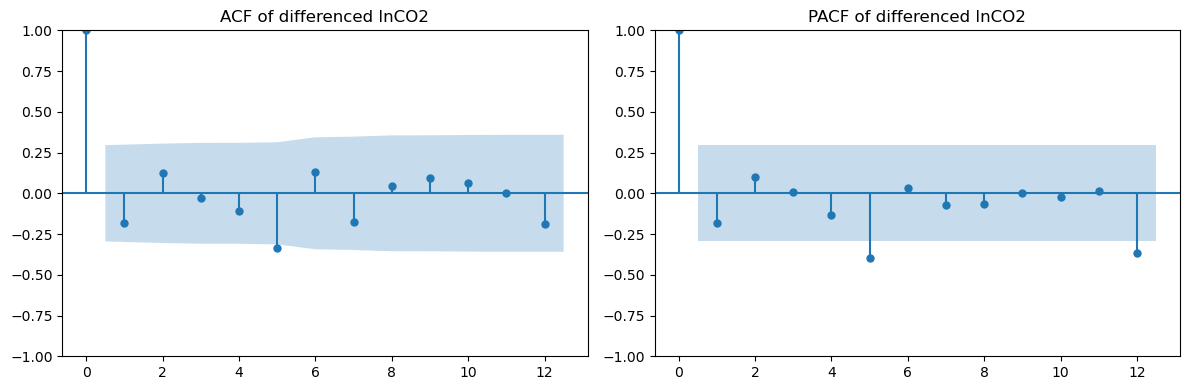

In [75]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

d = logs["lnCO2"].diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(d, lags=12, ax=ax[0], title="ACF of differenced lnCO2")
plot_pacf(d, lags=12, ax=ax[1], title="PACF of differenced lnCO2", method="ywm")
plt.tight_layout(); plt.show()

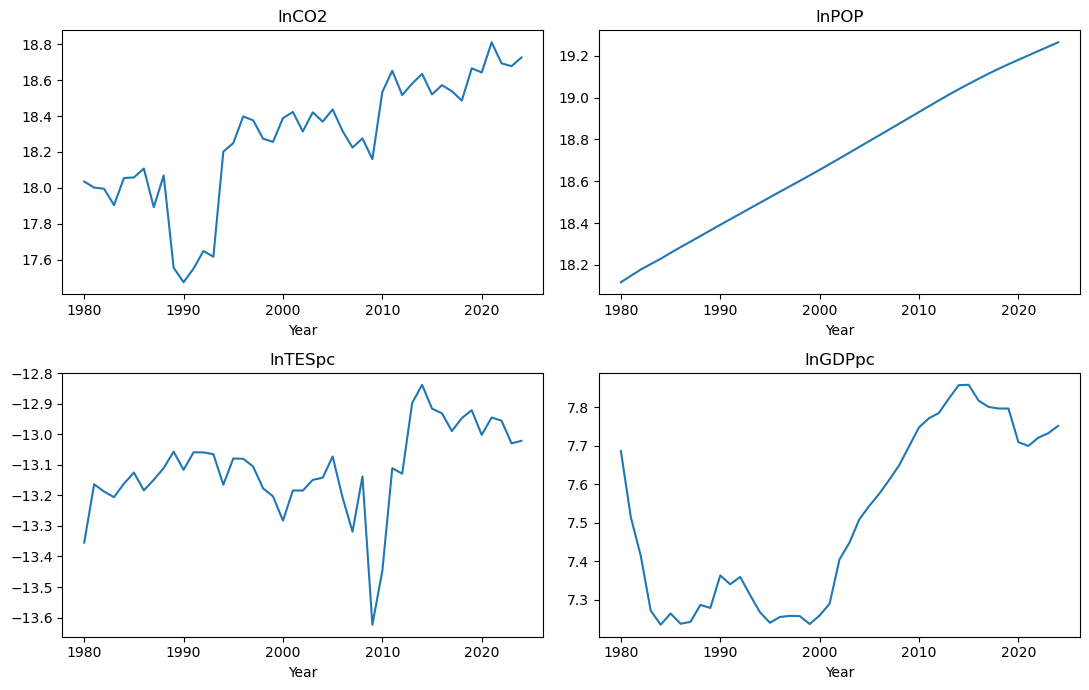

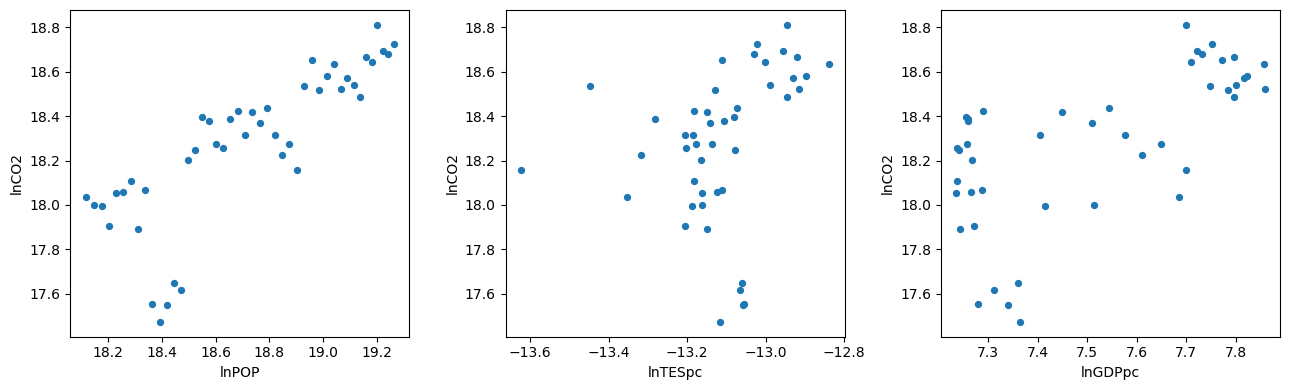

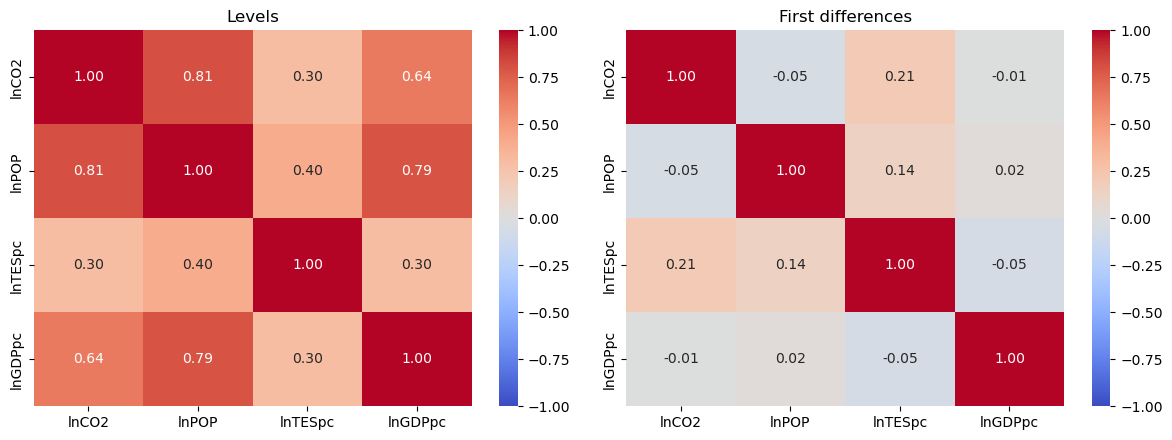

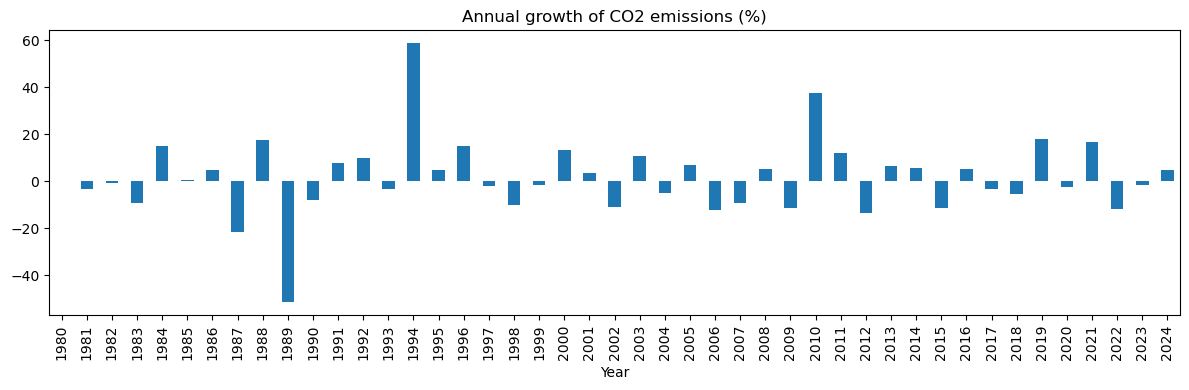

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["lnCO2", "lnPOP", "lnTESpc", "lnGDPpc"]

# 1. Time plots (Figure 4.1)
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), cols):
    logs[c].plot(ax=a, title=c); a.set_xlabel("Year")
plt.tight_layout(); plt.savefig("fig_timeplots.png", dpi=200); plt.show()

# 2. Scatter plots against lnCO2
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c in zip(ax, cols[1:]):
    a.scatter(logs[c], logs["lnCO2"], s=18); a.set_xlabel(c); a.set_ylabel("lnCO2")
plt.tight_layout(); plt.savefig("fig_scatter.png", dpi=200); plt.show()

# 3. Correlation heatmaps: levels and first differences
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(logs[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Levels")
sns.heatmap(logs[cols].diff().dropna().corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title("First differences")
plt.tight_layout(); plt.savefig("fig_corr.png", dpi=200); plt.show()

# 4. Annual growth rate of emissions (%)
(logs["lnCO2"].diff() * 100).plot(kind="bar", figsize=(12, 4), title="Annual growth of CO2 emissions (%)")
plt.tight_layout(); plt.savefig("fig_growth.png", dpi=200); plt.show()

In [82]:
print(logs["lnTES"].head(3))

Year
1980    4.761817
1981    4.983659
1982    4.989733
Name: lnTES, dtype: float64


In [83]:
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.tsa.ardl import UECM
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import jarque_bera

logs["lnTESpc"] = logs["lnTES"] - logs["lnPOP"]
y = logs["lnCO2"]
X = logs[["lnPOP", "lnTESpc", "lnGDPpc"]]
m = UECM(y, 1, X, order={"lnPOP":1, "lnTESpc":1, "lnGDPpc":2}, trend="c").fit()

print("=== SUMMARY ==="); print(m.summary())
bt = m.bounds_test(case=3)
print("=== BOUNDS ==="); print(bt); print(bt.crit_vals)

print("=== LONG-RUN ===")
b = m.params; V = m.cov_params(); rho = b["lnCO2.L1"]
for v in ["lnPOP.L1", "lnTESpc.L1", "lnGDPpc.L1"]:
    lr = -b[v] / rho
    g = pd.Series(0.0, index=b.index); g[v] = -1/rho; g["lnCO2.L1"] = b[v]/rho**2
    se = float(np.sqrt(g @ V @ g)); print(v, round(lr,3), "se", round(se,3), "z", round(lr/se,2))

print("=== DIAGNOSTICS ===")
res = (y.diff() - m.fittedvalues).dropna()
print("Residual SD:", round(res.std(), 4))
print(acorr_ljungbox(res, lags=[1,2,3,4]))
print("Jarque-Bera:", jarque_bera(res))
Xc = sm.add_constant(X)
print("VIF:", {c: round(variance_inflation_factor(Xc.values, i),1) for i, c in enumerate(Xc.columns) if c != "const"})

=== SUMMARY ===
                              UECM Model Results                              
Dep. Variable:                D.lnCO2   No. Observations:                   45
Model:               UECM(1, 1, 1, 2)   Log Likelihood                  30.162
Method:               Conditional MLE   S.D. of innovations             18.063
Date:                Wed, 18 Nov 2026   AIC                            -40.323
Time:                        11:11:40   BIC                            -22.482
Sample:                             2   HQIC                           -33.707
                                   45                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -8.4162      3.654     -2.304      0.027     -15.833      -0.999
lnCO2.L1        -0.4664      0.115     -4.039      0.000      -0.701      -0.232
lnPOP.L1         0.9445     

In [84]:
import numpy as np, pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.ardl import UECM

y = logs["lnCO2"]; X = logs[["lnPOP", "lnTESpc", "lnGDPpc"]]
ytr, Xtr = y.loc[:2019], X.loc[:2019]
test_years = list(range(2020, 2025))

# ARIMA benchmark: search p,q in 0..3 on the training years, pick lowest AIC
best = None
for p in range(4):
    for q in range(4):
        try:
            r = ARIMA(ytr, order=(p, 1, q), trend="t").fit()
            if best is None or r.aic < best[0]: best = (r.aic, (p, 1, q), r)
        except Exception: pass
print("ARIMA order:", best[1], "AIC:", round(best[0], 2))
f_arima = np.exp(best[2].forecast(5).values)

# ARDL: fit on 1980-2019, then forecast 2020-2024 one step at a time
m = UECM(ytr, 1, Xtr, order={"lnPOP":1, "lnTESpc":1, "lnGDPpc":2}, trend="c").fit()
b = m.params; hist = list(ytr.values)
for t in test_years:
    c, p1, p2 = logs.loc[t], logs.loc[t-1], logs.loc[t-2]
    dy = (b["const"] + b["lnCO2.L1"]*hist[-1]
          + b["lnPOP.L1"]*p1["lnPOP"] + b["lnTESpc.L1"]*p1["lnTESpc"] + b["lnGDPpc.L1"]*p1["lnGDPpc"]
          + b["D.lnPOP.L0"]*(c["lnPOP"]-p1["lnPOP"])
          + b["D.lnTESpc.L0"]*(c["lnTESpc"]-p1["lnTESpc"])
          + b["D.lnGDPpc.L0"]*(c["lnGDPpc"]-p1["lnGDPpc"])
          + b["D.lnGDPpc.L1"]*(p1["lnGDPpc"]-p2["lnGDPpc"]))
    hist.append(hist[-1] + dy)
f_ardl = np.exp(hist[-5:])

out = pd.DataFrame({"actual": np.exp(y.loc[2020:2024]).values, "ARDL": f_ardl, "ARIMA": f_arima}, index=test_years)
for n in ["ARDL", "ARIMA"]:
    out[n + " err %"] = (out[n] - out["actual"]) / out["actual"] * 100
print(out.round(1))
for n in ["ARDL", "ARIMA"]:
    e = out["actual"] - out[n]
    print(n, "RMSE", round(np.sqrt((e**2).mean())), "MAE", round(e.abs().mean()), "MAPE", round((e.abs()/out["actual"]).mean()*100, 2))

ARIMA order: (0, 1, 0) AIC: -24.84
           actual         ARDL        ARIMA  ARDL err %  ARIMA err %
2020  124899300.0  130954119.2  129946133.8         4.8          4.0
2021  147776620.0  157929138.0  132067027.6         6.9        -10.6
2022  131440936.0  152971197.3  134222537.1        16.4          2.1
2023  129376100.0  144263996.8  136413227.4        11.5          5.4
2024  135824000.0  148113624.9  138639672.7         9.0          2.1
ARDL RMSE 13971192 MAE 12983024 MAPE 9.73
ARIMA RMSE 8215209 MAE 6678166 MAPE 4.86


In [85]:
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("=== STATIONARITY ===")
rows = []
for col in ["lnCO2", "lnPOP", "lnTESpc", "lnGDPpc"]:
    for label, s in [("Level", logs[col]), ("1st diff", logs[col].diff().dropna())]:
        a_c = adfuller(s, regression="c", autolag="AIC")
        a_ct = adfuller(s, regression="ct", autolag="AIC")
        k = kpss(s, regression="ct", nlags="auto")
        rows.append([col, label, round(a_c[0],3), round(a_c[1],4), round(a_ct[0],3), round(a_ct[1],4), round(k[0],3), round(k[1],4)])
print(pd.DataFrame(rows, columns=["Variable","Form","ADF_c","p","ADF_ct","p","KPSS_ct","p"]).to_string(index=False))

print("=== ARIMA (all 45 years) ===")
print(ARIMA(logs["lnCO2"], order=(0,1,0), trend="t").fit().summary())

print("=== VIF, FIRST MODEL (total energy) ===")
Xt = sm.add_constant(logs[["lnPOP", "lnTES", "lnGDPpc"]])
print({c: round(variance_inflation_factor(Xt.values, i), 1) for i, c in enumerate(Xt.columns) if c != "const"})

=== STATIONARITY ===
Variable     Form  ADF_c      p  ADF_ct      p  KPSS_ct      p
   lnCO2    Level -1.368 0.5975  -2.977 0.1387    0.063 0.1000
   lnCO2 1st diff -4.347 0.0004  -4.340 0.0027    0.049 0.1000
   lnPOP    Level -1.868 0.3472  -0.938 0.9519    0.146 0.0502
   lnPOP 1st diff -1.781 0.3901  -2.163 0.5108    0.173 0.0273
 lnTESpc    Level -2.820 0.0554  -3.124 0.1006    0.119 0.0992
 lnTESpc 1st diff -4.021 0.0013  -3.967 0.0098    0.108 0.1000
 lnGDPpc    Level -1.292 0.6330  -2.279 0.4455    0.156 0.0419
 lnGDPpc 1st diff -4.562 0.0002  -4.402 0.0022    0.180 0.0234
=== ARIMA (all 45 years) ===
                               SARIMAX Results                                
Dep. Variable:                  lnCO2   No. Observations:                   45
Model:                 ARIMA(0, 1, 0)   Log Likelihood                  18.043
Date:                Wed, 18 Nov 2026   AIC                            -32.085
Time:                        11:15:31   BIC                        

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
plt.rcParams.update({"font.size": 14})
cols = ["lnCO2", "lnPOP", "lnTESpc", "lnGDPpc"]

# 1. Time plots
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, c in zip(ax.ravel(), cols):
    logs[c].plot(ax=a, title=c, lw=2); a.set_xlabel("Year")
plt.tight_layout(); plt.savefig("fig1_timeplots.png", dpi=250); plt.close()

# 2. Scatter plots
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, c in zip(ax, cols[1:]):
    a.scatter(logs[c], logs["lnCO2"], s=45); a.set_xlabel(c); a.set_ylabel("lnCO2")
plt.tight_layout(); plt.savefig("fig2_scatter.png", dpi=250); plt.close()

# 3. Growth chart
(logs["lnCO2"].diff() * 100).plot(kind="bar", figsize=(16, 6), title="Annual growth of CO2 emissions (%)")
plt.tight_layout(); plt.savefig("fig3_growth.png", dpi=250); plt.close()

# 4. ACF and PACF
d = logs["lnCO2"].diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_acf(d, lags=12, ax=ax[0]); plot_pacf(d, lags=12, ax=ax[1], method="ywm")
plt.tight_layout(); plt.savefig("fig4_acf_pacf.png", dpi=250); plt.close()

In [86]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
plt.rcParams.update({"font.size": 14})
cols = ["lnCO2", "lnPOP", "lnTESpc", "lnGDPpc"]

# 1. Time plots
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, c in zip(ax.ravel(), cols):
    logs[c].plot(ax=a, title=c, lw=2); a.set_xlabel("Year")
plt.tight_layout(); plt.savefig("fig1_timeplots.png", dpi=250); plt.close()

# 2. Scatter plots
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, c in zip(ax, cols[1:]):
    a.scatter(logs[c], logs["lnCO2"], s=45); a.set_xlabel(c); a.set_ylabel("lnCO2")
plt.tight_layout(); plt.savefig("fig2_scatter.png", dpi=250); plt.close()

# 3. Growth chart
(logs["lnCO2"].diff() * 100).plot(kind="bar", figsize=(16, 6), title="Annual growth of CO2 emissions (%)")
plt.tight_layout(); plt.savefig("fig3_growth.png", dpi=250); plt.close()

# 4. ACF and PACF
d = logs["lnCO2"].diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_acf(d, lags=12, ax=ax[0]); plot_pacf(d, lags=12, ax=ax[1], method="ywm")
plt.tight_layout(); plt.savefig("fig4_acf_pacf.png", dpi=250); plt.close()